# Sovereign curves: Treasury yield curves and rate risk from FedInvest prices

The pipeline fetches the Treasury's FedInvest end-of-day prices every weekday, loads them into a
Parquet lake with accrued interest and the dirty price, and builds three curves a day: FIA's exact
bootstrap, a Svensson fit of our own, and the Fed Board's GSW curve as the answer key. Every bill,
note and bond then gets its pricing error against each curve and its risk: DV01, modified
duration, convexity, key-rate DV01s and carry.

This notebook reads the committed sample (October 2026, and 15 September 2008 and 16 March 2020
for the truth check) after `local-development/run_local.py` has run it through the same fetch
stand-in, Glue loader and ECS engine code. It builds `_localrun/` first if it is not there.

In [1]:
import datetime as dt
import gzip
import json
import sys
import warnings
from pathlib import Path

warnings.simplefilter("ignore", SyntaxWarning)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT = Path.cwd()
for p in (PROJECT, PROJECT / "local-development", PROJECT / "glue-pythonshell", PROJECT / "ecs", PROJECT / "lambda-functions"):
    sys.path.insert(0, str(p))
RUN = PROJECT / "_localrun"
if not (RUN / "lake-bucket" / "risk").exists():
    import run_local
    run_local.main([])

import app
import load
import truth_check
from bond_analytics import dates, truth
from bond_analytics.fedinvest import parse_prices

pd.set_option("display.width", 160)
RAW, LAKE = RUN / "raw-bucket", load.FolderStore(RUN / "lake-bucket")

def lake_table(name):
    frames = [load.from_parquet(LAKE.get(k)) for k in LAKE.list(name + "/")]
    return pd.concat(frames, ignore_index=True)

def page(day):
    path = RAW / "raw" / "fedinvest" / f"date={day}" / "prices.html"
    return parse_prices(path.read_text(encoding="latin-1"), dt.date.fromisoformat(day))

prices, curves, params, errors, risk = (lake_table(t) for t in ("prices", "curves", "curve_params", "fit_errors", "risk"))
print(f"{prices.price_date.nunique()} price dates, {len(prices):,} security-days; "
      f"{len(curves):,} curve points, {len(errors):,} fit errors, {len(risk):,} risk rows")

fetch: staged 48 sample objects from data/sample


load: auctions loaded 2026-11-02 to 2026-11-02; fedinvest loaded 2008-09-15 to 2026-10-30; gsw loaded 2026-11-02 to 2026-11-02; nyfed loaded 2020-03-16 to 2026-10-30
load: 23 price dates in the lake, watermarks [('auctions', '2026-11-02'), ('fedinvest', '2026-10-30'), ('gsw', '2026-11-02'), ('nyfed', '2026-10-30')]


WARNING engine 22 of 23 Svensson fits ended on a bound; each is in curve_params and fit_errors


engine: dates 23; seconds 55.1; fits_on_a_bound ['2008-09-15:beta3', '2026-10-01:beta0', '2026-10-02:beta0', '2026-10-05:beta0', '2026-10-06:beta0', '2026-10-07:beta0', '2026-10-08:beta0', '2026-10-09:beta0', '2026-10-13:beta0', '2026-10-14:beta0', '2026-10-15:beta0', '2026-10-16:beta0', '2026-10-19:beta0', '2026-10-20:beta0', '2026-10-21:beta0', '2026-10-22:beta0', '2026-10-23:beta0', '2026-10-26:beta0', '2026-10-27:beta0', '2026-10-28:beta0', '2026-10-29:beta0', '2026-10-30:beta0']


23 price dates, 10,354 security-days; 768 curve points, 24,966 fit errors, 8,991 risk rows


## 1. Settlement is T+1, and the bills say so

FedInvest's price for a date is for settlement the next business day. A clean price cannot show
that: it is continuous across a coupon date whichever convention it was struck on. The bills can,
because a bill a few days from maturity is priced off a handful of days, and counting one day too
many collapses its yield. On Friday 30 October 2026, counting from the price date:

In [2]:
rows = []
for r in page("2026-10-30"):
    if r["security_type"] != "MARKET BASED BILL":
        continue
    maturity = dt.datetime.strptime(r["maturity_date"], "%m/%d/%Y").date()
    price = float(r["end_of_day"])
    for label, settle in (("T+0", dt.date(2026, 10, 30)), ("T+1", dates.settlement_date(dt.date(2026, 10, 30)))):
        days = (maturity - settle).days
        rows.append({"maturity": maturity, "settles": label, "days": days, "discount yield %": round((100 - price) / 100 * 360 / days * 100, 2)})
bills = pd.DataFrame(rows)
bills.pivot(index="maturity", columns="settles", values="discount yield %").head(6)

settles,T+0,T+1
maturity,,
2026-11-03,0.95,3.82
2026-11-05,1.94,3.88
2026-11-10,2.82,3.88
2026-11-12,2.98,3.88
2026-11-17,3.23,3.88
2026-11-19,3.30,3.88


Counted from Monday 2 November, the six shortest bills yield 3.82% and then 3.88%, flat; counted
from the price date, their yields climb from under 1%, because three days that are not in the price
are counted as if they were.

The coupon date then checks the accrued interest. Five notes between one and ten years paid a
coupon on 15 October 2026. With T+1, the trade on the 14th settles on the coupon date, so its
dirty price drops by the coupon that day, and dirty price plus the coupon paid runs on as the
other notes do:

In [3]:
frames = []
for d in ("2026-10-13", "2026-10-14", "2026-10-15", "2026-10-16"):
    q = load.from_parquet(LAKE.get(f"prices/date={d}/prices.parquet"))
    frames.append(q[(q.kind == "note") & q.dirty.notna()])
notes = pd.concat(frames)
notes["payer"] = notes.maturity.map(lambda m: m.day == 15 and m.month in (4, 10)) & (notes.maturity > dt.date(2026, 10, 15))
notes = notes[(notes.years > 1) & (notes.years < 10)]
wide = {c: notes.pivot(index="cusip", columns="price_date", values=c) for c in ("dirty", "clean")}
payer = notes.groupby("cusip").payer.first()
half = notes.groupby("cusip").coupon.first() / 2
days = sorted(notes.price_date.unique())
out = []
for a, b in zip(days, days[1:]):
    dd = wide["dirty"][b] - wide["dirty"][a]
    paid = half if str(a) == "2026-10-13" else 0
    out.append({"from": a, "to": b, "payers' dirty change": dd[payer].median(), "payers' dirty + coupon paid": (dd + paid)[payer].median(),
                "other notes' dirty change": dd[~payer].median(), "payers' clean change": (wide["clean"][b] - wide["clean"][a])[payer].median()})
print(f"{int(payer.sum())} payers, median half coupon {half[payer].median():.4f}; {int((~payer).sum())} other notes")
pd.DataFrame(out).round(4)

5 payers, median half coupon 1.9375; 186 other notes


,from,to,payers' dirty change,payers' dirty + coupon paid,other notes' dirty change,payers' clean change
0,2026-10-13,2026-10-14,-1.8960,-0.0210,0.0096,-0.0312
1,2026-10-14,2026-10-15,0.1034,0.1034,0.1995,0.0938
2,2026-10-15,2026-10-16,0.1241,0.1241,0.1235,0.0938


## 2. The truth check: every note and bond off GSW's curve

GSW's parameters for the day, through FIA's `relative_bond.price`, against FedInvest's clean price
plus accrued at T+1. Positive basis points mean the bond is cheap to the curve. Anything within three
months of maturity is left out, as GSW leave it out, and so are callable bonds.

In [4]:
TC = truth_check.run(RAW, truth_check.DATES)
rows = truth.table_rows(TC)
for d, day in rows.groupby("price_date"):
    display(truth.summarise(day, ["bucket", "kind"]).rename_axis(index=[str(d), "kind"]))

n  mean_price  mae_price  mean_bp  mae_bp
2008-09-15 kind                                            
0-1y       bill  17      -0.065      0.075    -20.8    22.0
           note  23      -0.001      0.049     -3.5     8.9
1-2y       note  29      -0.050      0.081     -2.7     5.2
2-3y       note  13      -0.087      0.088     -3.6     3.6
3-5y       note  30       0.184      0.185      4.7     4.8
5-7y       bond   2       0.301      0.301      4.0     4.0
           note   8      -0.627      0.627    -10.5    10.5
7-10y      bond   7       0.518      0.518      5.8     5.8
           note  12      -0.951      0.951    -12.3    12.3
10-15y     bond  14       0.363      0.387      3.1     3.3
15-20y     bond  10      -0.252      0.252     -1.7     1.7
20-25y     bond   5      -0.027      0.076     -0.2     0.5
25-30y     bond   5       0.157      0.157      0.9     0.9

n  mean_price  mae_price  mean_bp  mae_bp
2020-03-16 kind                                            
0-1y       bill  19      -0.216      0.216    -46.8    46.8
           bond   2       0.004      0.051      3.9     8.9
           note  39       0.012      0.051      2.4     8.8
1-2y       bond   3       0.073      0.107      4.2     7.0
           note  50      -0.013      0.038     -0.6     2.4
2-3y       bond   3       0.105      0.105      3.6     3.6
           note  37      -0.037      0.054     -1.6     2.2
3-5y       bond   3      -0.014      0.092      0.1     2.0
           note  54      -0.055      0.113     -1.0     2.6
5-7y       bond   5       0.227      0.227      3.2     3.2
           note  32       0.034      0.084      0.5     1.4
7-10y      bond   6       0.211      0.211      2.1     2.1
           note  12      -0.060      0.189     -0.7     2.1
10-15y     bond   2       0.074      0.074      0.6     0.6
15-20y     bond  10      -1.142      1.142     -5.4     5.4
20-25y     bond  20       1.040      1.080      4.3     4.4
25-30y     bond  20      -0.912      1.212     -3.3     4.5

n  mean_price  mae_price  mean_bp  mae_bp
2026-10-23 kind                                            
0-1y       bill  23      -0.014      0.015     -2.4     2.6
           bond   2       0.107      0.107     21.0    21.0
           note  38       0.004      0.011      0.6     2.0
1-2y       bond   2       0.219      0.219     17.3    17.3
           note  51       0.017      0.018      1.4     1.5
2-3y       bond   3       0.080      0.080      3.7     3.7
           note  40      -0.005      0.013     -0.2     0.6
3-5y       bond   2       0.045      0.083      1.4     2.4
           note  55       0.006      0.020      0.1     0.6
5-7y       note  32       0.104      0.104      2.1     2.1
7-10y      bond   1      -1.013      1.013    -13.9    13.9
           note  12       0.103      0.126      1.6     2.0
10-15y     bond  21      -0.396      0.396     -4.7     4.7
15-20y     bond  40       0.281      0.281      2.8     2.8
20-25y     bond  20       0.027      0.137      0.2     1.5
25-30y     bond  20      -0.247      0.247     -2.0     2.0

Pooled over every maturity, run status would compare unlike with unlike: every note under a year is
off-the-run, and short yields are noisy. Inside each bucket that holds an on-the-run issue the
comparison is like with like. In March 2020 the on-the-run issue is the worst-priced in all six
buckets that hold one; on 23 October 2026 the three differ by a basis point or two either way.

In [5]:
nb = rows[rows.kind != "bill"]
truth.run_status_within_buckets(nb)

run                on-the-run  first off-the-run  off-the-run  n off-the-run
price_date bucket                                                           
2008-09-15 1-2y           3.2                3.9          5.5             25
           3-5y           0.1                2.7          5.0             28
           7-10y         19.6               17.9          8.8             17
           25-30y         0.4                1.4          0.8              3
2020-03-16 1-2y          15.3                5.8          2.4             51
           2-3y           8.7                3.4          2.1             38
           3-5y          11.6                6.2          2.4             55
           5-7y           2.4                0.1          1.6             35
           7-10y          6.9                4.1          1.7             16
           25-30y        16.5               12.0          3.4             18
2026-10-23 1-2y           0.6                0.2          2.1             51
           2-3y           1.6                0.3          0.8             41
           3-5y           0.5                0.5          0.7             55
           5-7y           1.5                1.4          2.1             30
           7-10y          1.3                0.6          3.2             11
           15-20y         2.0                2.8          2.8             38
           25-30y         2.9                3.1          1.8             18

Three regressions guard the mechanics. A wrong accrued shows as a slope on the share of the coupon
period elapsed, near half a coupon; a wrong time axis as a slope on maturity; wrong cash flows as
a price error that grows with the coupon. The coupon slope is taken within buckets with on-the-run
issues left out, then again with the years since issue beside it, to tell a coupon effect from
old-bond liquidity.

In [6]:
checks = []
for d, day in nb[nb.coupon > 0].groupby("price_date"):
    elapsed = day.accrued / (day.coupon / 2)
    day = day.assign(age=[(pd.Timestamp(d) - pd.Timestamp(i)).days / 365.25 if i is not None and i == i else np.nan for i in day.issue_date])
    bp, px, both = truth.coupon_slope(day, "error_bp"), truth.coupon_slope(day, "error_price"), truth.coupon_slope(day, "error_bp", extra=("age",))
    checks.append({"price_date": d, "half coupon (median)": (day.coupon / 2).median(),
                   "slope on period elapsed": np.polyfit(elapsed, day.error_price, 1)[0],
                   "slope per 10y of maturity": np.polyfit(day.years, day.error_price, 1)[0] * 10,
                   "price per coupon point": f"{px['slope']:+.3f} ({px['se']:.3f})",
                   "bp per coupon point": f"{bp['slope']:+.2f} ({bp['se']:.2f})",
                   "bp per coupon point, age held": f"{both['slope']:+.2f} ({both['se']:.2f})",
                   "bp per year since issue": f"{both['slope_age']:+.2f} ({both['se_age']:.2f})"})
pd.DataFrame(checks).set_index("price_date").round(3).T

price_date,2008-09-15,2020-03-16,2026-10-23
half coupon (median),2.25,1.125,1.938
slope on period elapsed,0.04,0.068,0.027
slope per 10y of maturity,-0.006,-0.097,-0.018
price per coupon point,+0.165 (0.016),+0.012 (0.016),+0.005 (0.006)
bp per coupon point,+2.25 (0.40),+0.54 (0.21),+0.56 (0.13)
"bp per coupon point, age held",+0.95 (0.69),-0.11 (0.47),+0.47 (0.13)
bp per year since issue,+0.45 (0.20),+0.16 (0.10),+0.18 (0.03)


## 3. A quote the loader flags and keeps

The largest pricing error on 23 October 2026 is a 6.5% bond three weeks from maturity. Two notes
mature the same day, and the bills price all three without a fitted curve:

In [7]:
p23 = load.from_parquet(LAKE.get("prices/date=2026-10-23/prices.parquet"))
same_day = p23[p23.maturity == dt.date(2026, 11, 15)][["cusip", "kind", "coupon", "buy", "sell", "clean", "accrued", "dirty", "bill_curve_gap", "neighbour_gap_ticks", "quality_flags"]]
same_day.assign(gap_32nds=same_day.bill_curve_gap * 32).round(4)

,cusip,kind,coupon,buy,sell,clean,accrued,dirty,bill_curve_gap,neighbour_gap_ticks,quality_flags,gap_32nds
52,91282CJK8,note,4.625,0.0,100.0312,100.0000,2.0611,102.0611,-0.0301,-0.4401,,-0.9621
53,912828U24,note,2.000,0.0,99.8750,99.8750,0.8913,100.7663,-0.0152,0.1589,,-0.4877
290,912810EY0,bond,6.500,0.0,99.9688,99.9062,2.8967,102.8030,-0.2237,-6.6361,off_neighbours,-7.1581


The notes are within a 32nd of the bills, which is the quote's own rounding; the bond is seven 32nds
low. The loader keeps the price as quoted and adds `off_neighbours`, which fires when a quote sits
more than four 32nds from the median gap of the notes and bonds maturing within 31 days of it.
Over the sample:

In [8]:
checked = prices.neighbour_gap_ticks.dropna()
flagged = prices[prices.quality_flags.str.contains("off_neighbours")]
print(f"{len(checked):,} quotes checked against their neighbours: median |gap| {checked.abs().median():.2f}, "
      f"90th percentile {checked.abs().quantile(0.9):.2f} 32nds; {len(flagged)} flagged")
flagged.groupby(["cusip", "coupon", "maturity"]).agg(days=("price_date", "size"), median_32nds=("neighbour_gap_ticks", "median")).round(2)

1,188 quotes checked against their neighbours: median |gap| 0.40, 90th percentile 1.42 32nds; 41 flagged


,,,days,median_32nds
cusip,coupon,maturity,,
912810EY0,6.500,2026-11-15,18,-6.14
912810EZ7,6.625,2027-02-15,8,-4.85
912810FA1,6.375,2027-08-15,14,-5.40
9128285G1,2.875,2020-10-31,1,-4.76


## 4. Three curves

FIA's bootstrap goes through 40 to 45 bonds a day exactly, one per maturity bucket, bills under a year and
off-the-run notes and bonds beyond. Our Svensson fit minimises duration-weighted price errors over
the notes and bonds GSW would use. GSW's own curve is the third. On 23 October 2026:

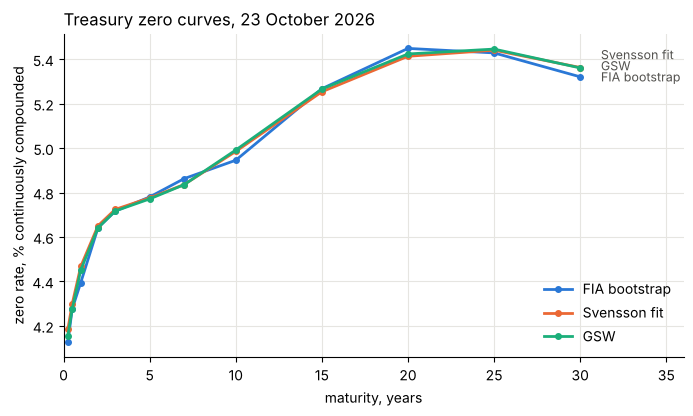

tenor,0.25,0.50,1.00,2.00,3.00,5.00,7.00,10.00,15.00,20.00,25.00,30.00
curve,,,,,,,,,,,,
"fia_bootstrap - GSW, bp",-3.0,0.0,-5.7,-0.0,-0.1,0.9,2.7,-4.6,0.2,2.5,-1.7,-4.0
"svensson - GSW, bp",2.8,2.3,1.6,0.9,0.7,0.5,0.1,-0.6,-1.2,-1.0,-0.5,0.2


In [9]:
c = curves[curves.price_date == dt.date(2026, 10, 23)].pivot(index="tenor", columns="curve", values="zero_rate")
SERIES = {"fia_bootstrap": ("#2a78d6", "FIA bootstrap"), "svensson": ("#eb6834", "Svensson fit"), "gsw": ("#1baf7a", "GSW")}
fig, ax = plt.subplots(figsize=(8, 4.2))
ends, gap = {}, 0.05  # direct labels at the 30-year end, nudged apart where the curves meet
for name in sorted(SERIES, key=lambda n: c[n].iloc[-1]):
    y = c[name].iloc[-1]
    ends[name] = max(y, max(ends.values(), default=-1e9) + gap)
for name, (colour, label) in SERIES.items():
    ax.plot(c.index, c[name], color=colour, lw=2, marker="o", ms=4, label=label)
    ax.annotate(label, (c.index[-1], c[name].iloc[-1]), xytext=(31.2, ends[name]), textcoords="data", va="center", fontsize=9, color="#52514e")
ax.set_xlabel("maturity, years"); ax.set_ylabel("zero rate, % continuously compounded")
ax.set_title("Treasury zero curves, 23 October 2026", loc="left")
ax.grid(color="#e6e5e1", lw=0.8); ax.spines[["top", "right"]].set_visible(False); ax.set_xlim(0, 36)
ax.legend(frameon=False, loc="lower right")
plt.show()
((c[["fia_bootstrap", "svensson"]].sub(c["gsw"], axis=0)) * 100).round(1).T.rename(index=lambda s: s + " - GSW, bp")

Every Svensson fit is recorded with the parameters that ended on a bound of the search. In October
2026 that is `beta0`, the long-run level, at zero, which is where GSW's own fit puts it (5.5e-13 on
the 23rd); in September 2008 it is `beta3`, because the two humps' decay parameters were nearly
equal and their loadings trade off.

In [10]:
sv = params[params.curve == "svensson"].sort_values("price_date")
print(sv.params_at_bound.replace("", "none").value_counts().to_string())
both = params[params.curve.isin(["svensson", "gsw"]) & params.price_date.isin([dt.date(2008, 9, 15), dt.date(2020, 3, 16), dt.date(2026, 10, 23)])]
both.set_index(["price_date", "curve"])[["beta0", "beta1", "beta2", "beta3", "tau1", "tau2", "rmse_bp", "n_bonds", "params_at_bound"]].round(3)

params_at_bound
beta0    21
beta3     1
none      1


beta0  beta1   beta2   beta3   tau1    tau2  rmse_bp  n_bonds params_at_bound
price_date curve                                                                                  
2008-09-15 svensson  2.541 -1.037 -54.974  60.000  4.690   5.210    7.651    148.0           beta3
           gsw       3.047 -1.431 -25.314  28.559  3.983   4.939      NaN      NaN                
2020-03-16 svensson  3.094 -2.060  -3.015  -5.513  1.385   7.419    5.570    286.0                
           gsw       3.226 -2.284  -2.884  -5.707  1.546   7.877      NaN      NaN                
2026-10-23 svensson  0.000  4.046   4.465  16.115  1.964  16.046    3.139    301.0           beta0
           gsw       0.000  4.010   4.512  16.154  1.923  15.833      NaN      NaN

## 5. Fit errors against FedInvest

Notes and bonds three months or more from maturity, every sample date, mean absolute error by
curve. The bootstrap is exact on its own knots and interpolates between them; the two Svensson
curves are smooth and miss everything a little.

In [11]:
fe = errors[(errors.years >= 0.25) & ~errors.callable & errors.kind.isin(["note", "bond"])]
fe.groupby("curve").agg(security_days=("error_bp", "size"), mae_bp=("error_bp", lambda s: s.abs().mean()),
                        mae_price=("error_price", lambda s: s.abs().mean()), knots_or_fit=("in_fit", "sum")).round(3)

,security_days,mae_bp,mae_price,knots_or_fit
curve,,,,
fia_bootstrap,7573,2.255,0.047,865
gsw,5880,2.296,0.120,5251
svensson,7573,2.266,0.123,6754


## 6. Risk

On the fitted curve shifted by each bond's own z-spread, so it reprices the bond exactly, a
one-basis-point bump at each key tenor in the shape of a triangle gives the key-rate DV01s. The
triangles add to one, so the five add to the curve DV01 of a parallel shift. DV01, modified
duration and convexity are on the bond's own semiannual yield, through FIA's `YTM`,
`create_flat_curve`, `dollar`, `duration` and `convexity`. Carry is the coupon income over 30
days less financing the dirty price at the day's funding rate. The on-the-run issues on
30 October 2026, per 100 face:

In [12]:
k = [c for c in risk.columns if c.startswith("krd_")]
rel = ((risk[k].sum(axis=1) - risk.curve_dv01).abs() / risk.curve_dv01.abs()).max()
print(f"{len(risk):,} security-days; largest |sum of key rates - curve DV01| relative to it: {rel:.1e}")
f30 = params[(params.curve == "svensson") & (params.price_date == dt.date(2026, 10, 30))].iloc[0]
print(f"funding on 30 October 2026: {f30.funding_rate:.2f}% ({f30.funding_source})")
otr = risk[(risk.price_date == dt.date(2026, 10, 30)) & (risk.run == "on-the-run")].sort_values("years")
otr[["cusip", "coupon", "maturity", "ytm", "dv01", "modified_duration", "convexity", "z_spread_bp", "carry_30d"] + k].round(4)

8,991 security-days; largest |sum of key rates - curve DV01| relative to it: 6.7e-07
funding on 30 October 2026: 3.95% (SOFR)


,cusip,coupon,maturity,ytm,dv01,modified_duration,convexity,z_spread_bp,carry_30d,krd_2y,krd_5y,krd_10y,krd_20y,krd_30y
8736,91282CRP8,4.750,2028-09-30,4.5712,0.0181,1.8013,4.1977,-2.0006,0.0599,0.0186,0.0000,0.0000,0.0000,0.0000
8779,91282CRQ6,4.875,2029-10-15,4.6437,0.0274,2.7160,8.9803,-2.1376,0.0698,0.0196,0.0085,0.0000,0.0000,0.0000
8834,91282CRN3,5.000,2031-09-30,4.7183,0.0437,4.2969,21.8843,-0.8992,0.0774,0.0041,0.0406,0.0000,0.0000,0.0000
8866,91282CRM5,5.000,2033-09-30,4.8107,0.0586,5.7696,39.5592,1.4879,0.0778,0.0029,0.0370,0.0201,0.0000,0.0000
8878,91282CRF0,4.625,2036-08-15,4.9289,0.0758,7.6867,71.6316,-0.5040,0.0523,0.0027,0.0105,0.0644,0.0000,0.0000
8950,912810UX4,5.125,2046-08-15,5.3383,0.1192,12.0964,200.1156,2.8721,0.0935,0.0030,0.0087,0.0254,0.0838,0.0000
8990,912810UW6,5.125,2056-08-15,5.3134,0.1456,14.8171,331.1038,-3.3431,0.0943,0.0030,0.0087,0.0242,0.0358,0.0752


The funding leg is SOFR from April 2018, and before it the money-market yield of the bill nearest
four weeks out stands in. On 15 September 2008 that bill yielded 0.46%:

In [13]:
params[params.curve == "svensson"].groupby("funding_source").agg(days=("price_date", "size"), first=("price_date", "min"),
    mean_rate=("funding_rate", "mean")).round(2)

,days,first,mean_rate
funding_source,,,
4-week bill,1,2008-09-15,0.46
SOFR,22,2020-03-16,3.73


## 7. The watermark

Each source's last loaded date sits in `control/watermarks.json`, the engine's beside them. Run
the load and the engine again, incrementally, and both find nothing to do:

In [14]:
raw = load.FolderStore(RAW)
print(load.run(raw, LAKE, "incremental"))
print(app.run(LAKE, "incremental"))
{s: m["loaded_through"] for s, m in load.read_watermarks(LAKE).items()}

{'auctions': 'nothing new', 'fedinvest': 'nothing new', 'gsw': 'nothing new', 'nyfed': 'nothing new'}


{'dates': 0, 'seconds': 0.0, 'fits_on_a_bound': 'none'}


{'auctions': '2026-11-02',
 'engine': '2026-10-30',
 'fedinvest': '2026-10-30',
 'gsw': '2026-11-02',
 'nyfed': '2026-10-30'}

## 8. Time

The bootstrap is FIA's own pure-Python Newton solver, one knot at a time; the Svensson fit is
`scipy.optimize.least_squares` from six starting points, one of them the day before's answer.

In [15]:
t = params.pivot_table(index="curve", values="seconds", aggfunc=["mean", "max", "count"]).dropna()
t.columns = ["mean seconds", "max seconds", "dates"]
t.round(3)

,mean seconds,max seconds,dates
curve,,,
fia_bootstrap,0.019,0.031,23
svensson,2.105,4.217,23
